**EXP - 05 IMPLEMENTATION OF A RECURRENT NEURAL NETWORK (RNN) FOR TEXT GENERATION**

**Vishal S 24BAD130**

**PART A: DATASET PREPARATION**

In [ ]:
# RNN Text Generation using Tiny Shakespeare Dataset

!pip install -q datasets tensorflow matplotlib numpy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from datasets import load_dataset

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

print("Vishal S")
print("24BAD130")

TensorFlow Version: 2.20.0
NumPy Version: 2.1.3
Vishal S
24BAD130


In [ ]:
# Roll No: YOUR_ROLL_NO

from datasets import load_dataset

dataset = load_dataset("Trelis/tiny-shakespeare")

print(dataset)

README.md:   0%|          | 0.00/497 [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/1.22M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/119k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/472 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/49 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Text'],
        num_rows: 472
    })
    test: Dataset({
        features: ['Text'],
        num_rows: 49
    })
})


In [ ]:
print(dataset["train"][0])

{'Text': "First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you know Caius Marcius is chief enemy to the people.\n\nAll:\nWe know't, we know't.\n\nFirst Citizen:\nLet us kill him, and we'll have corn at our own price.\nIs't a verdict?\n\nAll:\nNo more talking on't; let it be done: away, away!\n\nSecond Citizen:\nOne word, good citizens.\n\nFirst Citizen:\nWe are accounted poor citizens, the patricians good.\nWhat authority surfeits on would relieve us: if they\nwould yield us but the superfluity, while it were\nwholesome, we might guess they relieved us humanely;\nbut they think we are too dear: the leanness that\nafflicts us, the object of our misery, is as an\ninventory to particularise their abundance; our\nsufferance is a gain to them Let us revenge this with\nour pikes, ere we become rakes: for the gods know I\nspeak this i

In [ ]:
#Explore the Dataset

print("Number of training samples:", len(dataset["train"]))

print("\nFirst 1000 characters of training text:")
print(dataset["train"][0]["Text"][:1000])

Number of training samples: 472

First 1000 characters of training text:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the

In [ ]:
text = dataset["train"][0]["Text"]
text = text.lower()

print("Text after lowercase conversion:")
print(text[:500])

Text after lowercase conversion:
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us kill him, and we'll have corn at our own price.
is't a verdict?

all:
no more talking on't; let it be done: away, away!

second citizen:
one word, good citizens.

first citizen:
we are accounted poor


In [ ]:
#Tokenize Text into Words

words = text.split()

print("Total number of words:", len(words))

print("\nFirst 30 words:")
print(words[:30])

Total number of words: 554

First 30 words:
['first', 'citizen:', 'before', 'we', 'proceed', 'any', 'further,', 'hear', 'me', 'speak.', 'all:', 'speak,', 'speak.', 'first', 'citizen:', 'you', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than', 'to', 'famish?', 'all:', 'resolved.', 'resolved.', 'first', 'citizen:']


In [ ]:
# Build Vocabulary

vocab = sorted(set(words))

word_to_index = {
    word: index + 1
    for index, word in enumerate(vocab)
}

index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

vocab_size = len(word_to_index) + 1

print("Vocabulary Size:", vocab_size)

print("\nSample Vocabulary:")
for word in list(word_to_index.keys())[:20]:
    print(word, ":", word_to_index[word])

Vocabulary Size: 295

Sample Vocabulary:
'em : 1
a : 2
abundance; : 3
account : 4
accounted : 5
accusations; : 6
afflicts : 7
against : 8
agrippa; : 9
all : 10
all: : 11
already. : 12
altitude : 13
always : 14
an : 15
and : 16
any : 17
appear : 18
are : 19
arms : 20


In [ ]:
# Convert Words To Numerical

encoded_words = [
    word_to_index[word]
    for word in words
]

print("First 30 words:")
print(words[:30])

print("\nNumerical representation:")
print(encoded_words[:30])

First 30 words:
['first', 'citizen:', 'before', 'we', 'proceed', 'any', 'further,', 'hear', 'me', 'speak.', 'all:', 'speak,', 'speak.', 'first', 'citizen:', 'you', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than', 'to', 'famish?', 'all:', 'resolved.', 'resolved.', 'first', 'citizen:']

Numerical representation:
[85, 46, 32, 269, 191, 17, 92, 108, 150, 221, 11, 220, 221, 85, 46, 290, 19, 10, 200, 195, 252, 70, 237, 252, 82, 11, 201, 201, 85, 46]


In [ ]:
# Generate Input Sequences

sequence_length = 10

sequences = []

for i in range(1, len(encoded_words)):

    start = max(0, i - sequence_length)

    sequence = encoded_words[start:i+1]

    sequences.append(sequence)

print("Number of generated sequences:", len(sequences))

print("\nFirst 5 sequences:")
for sequence in sequences[:5]:
    print(sequence)

Number of generated sequences: 553

First 5 sequences:
[85, 46]
[85, 46, 32]
[85, 46, 32, 269]
[85, 46, 32, 269, 191]
[85, 46, 32, 269, 191, 17]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Apply Sequence Padding

padded_sequences = pad_sequences(
    sequences,
    maxlen=sequence_length + 1,
    padding="pre"
)

print("Padded sequence shape:", padded_sequences.shape)

print("\nFirst 5 padded sequences:")
print(padded_sequences[:5])

Padded sequence shape: (553, 11)

First 5 padded sequences:
[[  0   0   0   0   0   0   0   0   0  85  46]
 [  0   0   0   0   0   0   0   0  85  46  32]
 [  0   0   0   0   0   0   0  85  46  32 269]
 [  0   0   0   0   0   0  85  46  32 269 191]
 [  0   0   0   0   0  85  46  32 269 191  17]]


In [ ]:
# Create Input and Target

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (553, 10)
Target shape: (553,)


In [ ]:
# Split into Training and Validation Data

split_index = int(0.8 * len(X))

X_train = X[:split_index]
y_train = y[:split_index]

X_val = X[split_index:]
y_val = y[split_index:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

print("\nTraining input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nValidation input shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

Training samples: 442
Validation samples: 111

Training input shape: (442, 10)
Training target shape: (442,)

Validation input shape: (111, 10)
Validation target shape: (111,)


**PART B — IMPLEMENTING THE RNN MODEL**

In [ ]:
# Create RNN Model

embedding_dim = 128
rnn_units = 128

model = tf.keras.Sequential([

    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    tf.keras.layers.SimpleRNN(
        rnn_units
    ),

    tf.keras.layers.Dense(
        vocab_size,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("RNN Model Created Successfully!")

RNN Model Created Successfully!


In [ ]:
#Model Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**PART C — TRAINING AND EVALUATION**

In [ ]:
# Train the RNN

epochs = 10
batch_size = 128

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 148ms/step - accuracy: 0.0068 - loss: 5.6902 - val_accuracy: 0.0000e+00 - val_loss: 5.6944
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.0950 - loss: 5.5827 - val_accuracy: 0.0090 - val_loss: 5.7039
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1719 - loss: 5.4648 - val_accuracy: 0.0090 - val_loss: 5.7563
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.0814 - loss: 5.2992 - val_accuracy: 0.0090 - val_loss: 5.9031
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0566 - loss: 5.1663 - val_accuracy: 0.0180 - val_loss: 5.9461
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.0837 - loss: 5.0079 - val_accuracy: 0.0090 - val_loss: 5.8701
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1742 - loss: 4.8483 - val_accuracy: 0.0090 - val_loss: 5.9317
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1833 - loss: 4.6690 - val_accuracy: 0.0180 - val_loss: 6.

In [ ]:
# Display Training Results

train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print("Final Training Accuracy :", train_accuracy)
print("Final Validation Accuracy:", val_accuracy)

print("Final Training Loss     :", train_loss)
print("Final Validation Loss   :", val_loss)

Final Training Accuracy : 0.2579185664653778
Final Validation Accuracy: 0.018018018454313278
Final Training Loss     : 4.296998977661133
Final Validation Loss   : 6.219262599945068


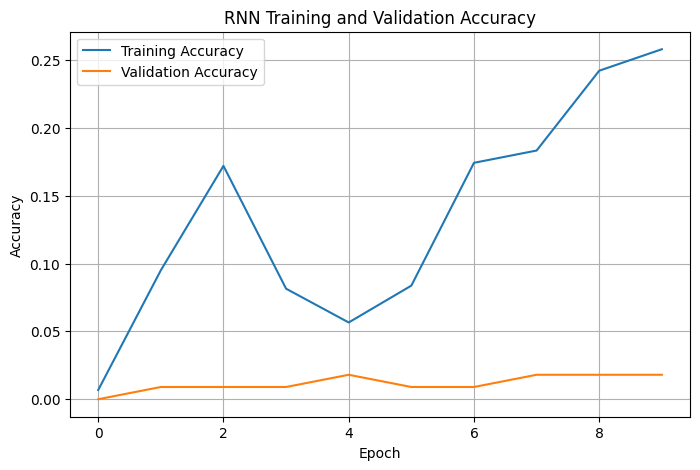

In [ ]:
# Accuracy vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("RNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

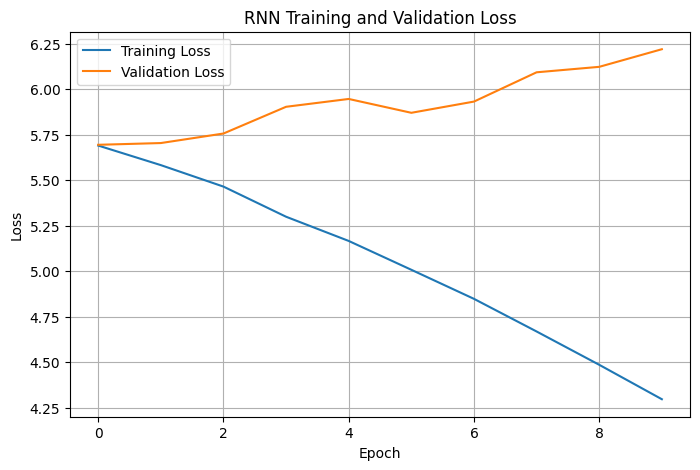

In [ ]:
# Loss vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

**PART D — TEXT GENERATION**

In [ ]:
# Create Text Generation Function

def generate_text(seed_text, next_words=30):

    generated_words = seed_text.lower().split()

    for _ in range(next_words):

        current_words = generated_words[-sequence_length:]

        encoded = [
            word_to_index.get(word, 0)
            for word in current_words
        ]

        padded = pad_sequences(
            [encoded],
            maxlen=sequence_length,
            padding="pre"
        )

        prediction = model.predict(
            padded,
            verbose=0
        )

        next_word_index = np.argmax(prediction[0])

        next_word = index_to_word.get(
            next_word_index,
            ""
        )

        if next_word == "":
            break

        generated_words.append(next_word)

    return " ".join(generated_words)

In [ ]:
# Generate Text from One Seed

seed_text = "to be or not"

generated_text = generate_text(
    seed_text,
    next_words=30
)

print("Seed Text:")
print(seed_text)

print("\nGenerated Text:")
print(generated_text)

Seed Text:
to be or not

Generated Text:
to be or not all: what to citizen: citizen: in citizen: citizen: be he citizen: first he accounted is the citizen: not second citizen: not second citizen: to to the first to to we


In [ ]:
# Generate Multiple Text Samples

seed_texts = [
    "to be or not",
    "the king",
    "my lord",
    "what is",
    "good sir"
]

for seed in seed_texts:

    print("=" * 70)
    print("Seed:", seed)

    generated = generate_text(
        seed,
        next_words=25
    )

    print("Generated Text:")
    print(generated)
    print()

Seed: to be or not
Generated Text:
to be or not all: what to citizen: citizen: in citizen: citizen: be he citizen: first he accounted is the citizen: not second citizen: not second citizen: to to

Seed: the king
Generated Text:
the king capitol! all: have citizen: second citizen: what he to to the citizen: to to to the citizen: citizen: to he the citizen: to he to

Seed: my lord
Generated Text:
my lord countrymen, first: citizen: who very it the the he second citizen: to citizen: citizen: to to to the citizen: to citizen: we the citizen: to

Seed: what is
Generated Text:
what is capitol! all: what more we citizen: in citizen: we to to citizen: second citizen: we you is the citizen: to to to the the first

Seed: good sir
Generated Text:
good sir humanely; he on't; wants, to in us the citizen: to citizen: citizen: citizen: to he to to the citizen: to the citizen: the he citizen:

